# Practical Assignment 2

#### 1: Comparative Edge Detection on Natural Images

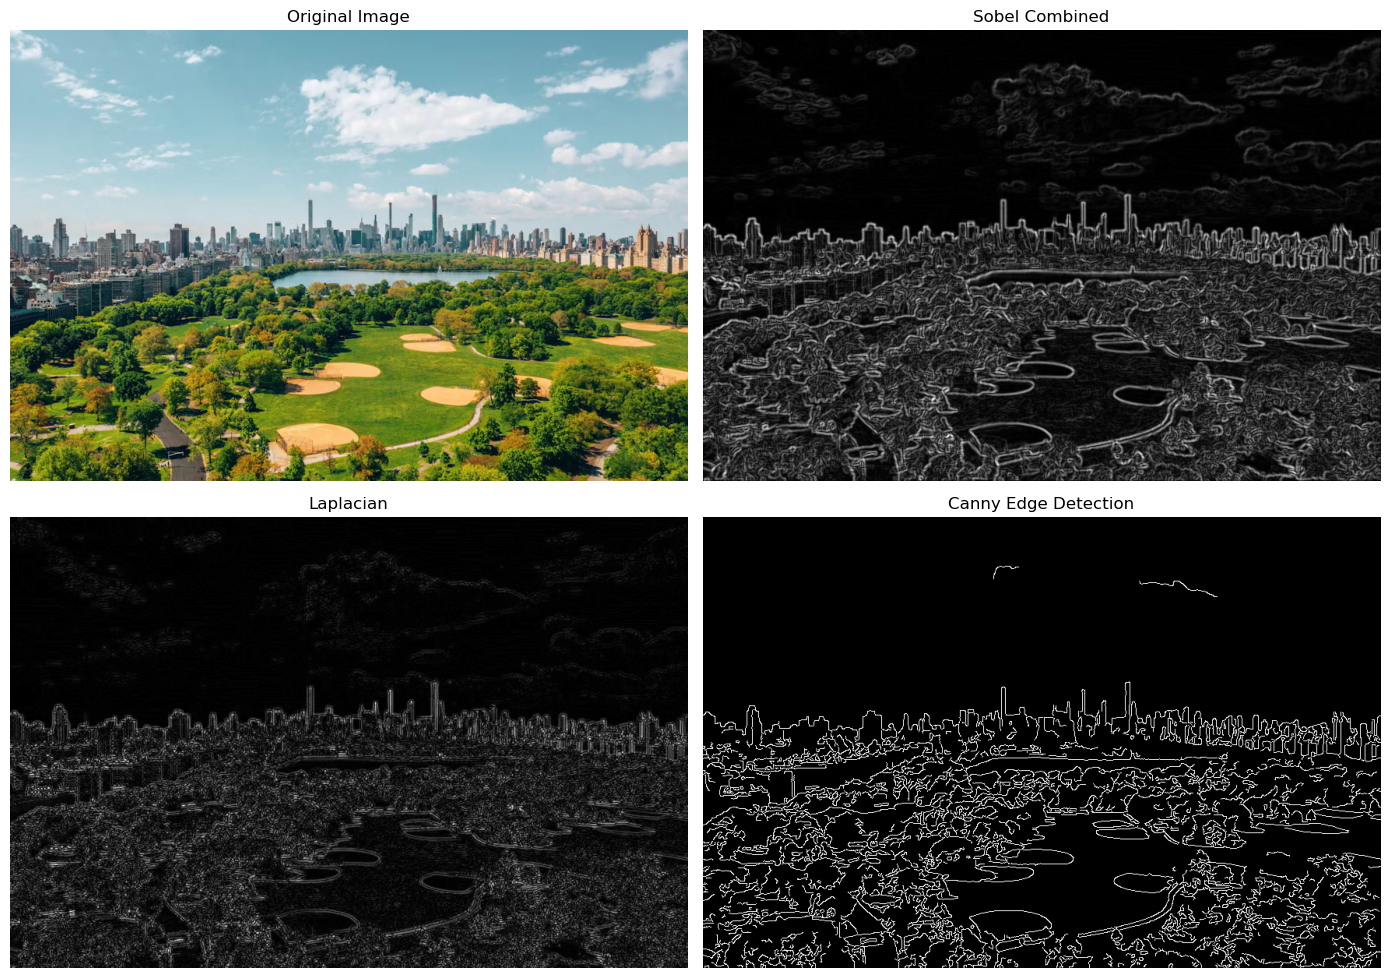

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. Load the provided outdoor natural image
img = cv2.imread('nature.jpg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Preprocessing: 5x5 Gaussian blur to stabilize edge operators
blurred = cv2.GaussianBlur(gray, (5, 5), 1)

# Operator 1: Sobel (Combined X and Y gradients)
sobel_x = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel_x_abs = cv2.convertScaleAbs(sobel_x)
sobel_y_abs = cv2.convertScaleAbs(sobel_y)
sobel_combined = cv2.addWeighted(sobel_x_abs, 0.5, sobel_y_abs, 0.5, 0)

# Operator 2: Laplacian (Second-order derivative)
laplacian = cv2.Laplacian(blurred, cv2.CV_64F, ksize=3)
laplacian_abs = cv2.convertScaleAbs(laplacian)

# Operator 3: Canny (Non-maximum suppression & hysteresis)
canny = cv2.Canny(blurred, 100, 200)

# Display Comparison
plt.figure(figsize=(14, 10))
plt.subplot(2, 2, 1)
plt.imshow(img_rgb)
plt.title('Original Image')
plt.axis('off')
plt.subplot(2, 2, 2)
plt.imshow(sobel_combined, cmap='gray')
plt.title('Sobel Combined')
plt.axis('off')
plt.subplot(2, 2, 3)
plt.imshow(laplacian_abs, cmap='gray')
plt.title('Laplacian')
plt.axis('off')
plt.subplot(2, 2, 4)
plt.imshow(canny, cmap='gray')
plt.title('Canny Edge Detection')
plt.axis('off')
plt.tight_layout()
plt.show()

#### 2: Noise Sensitivity Experiment

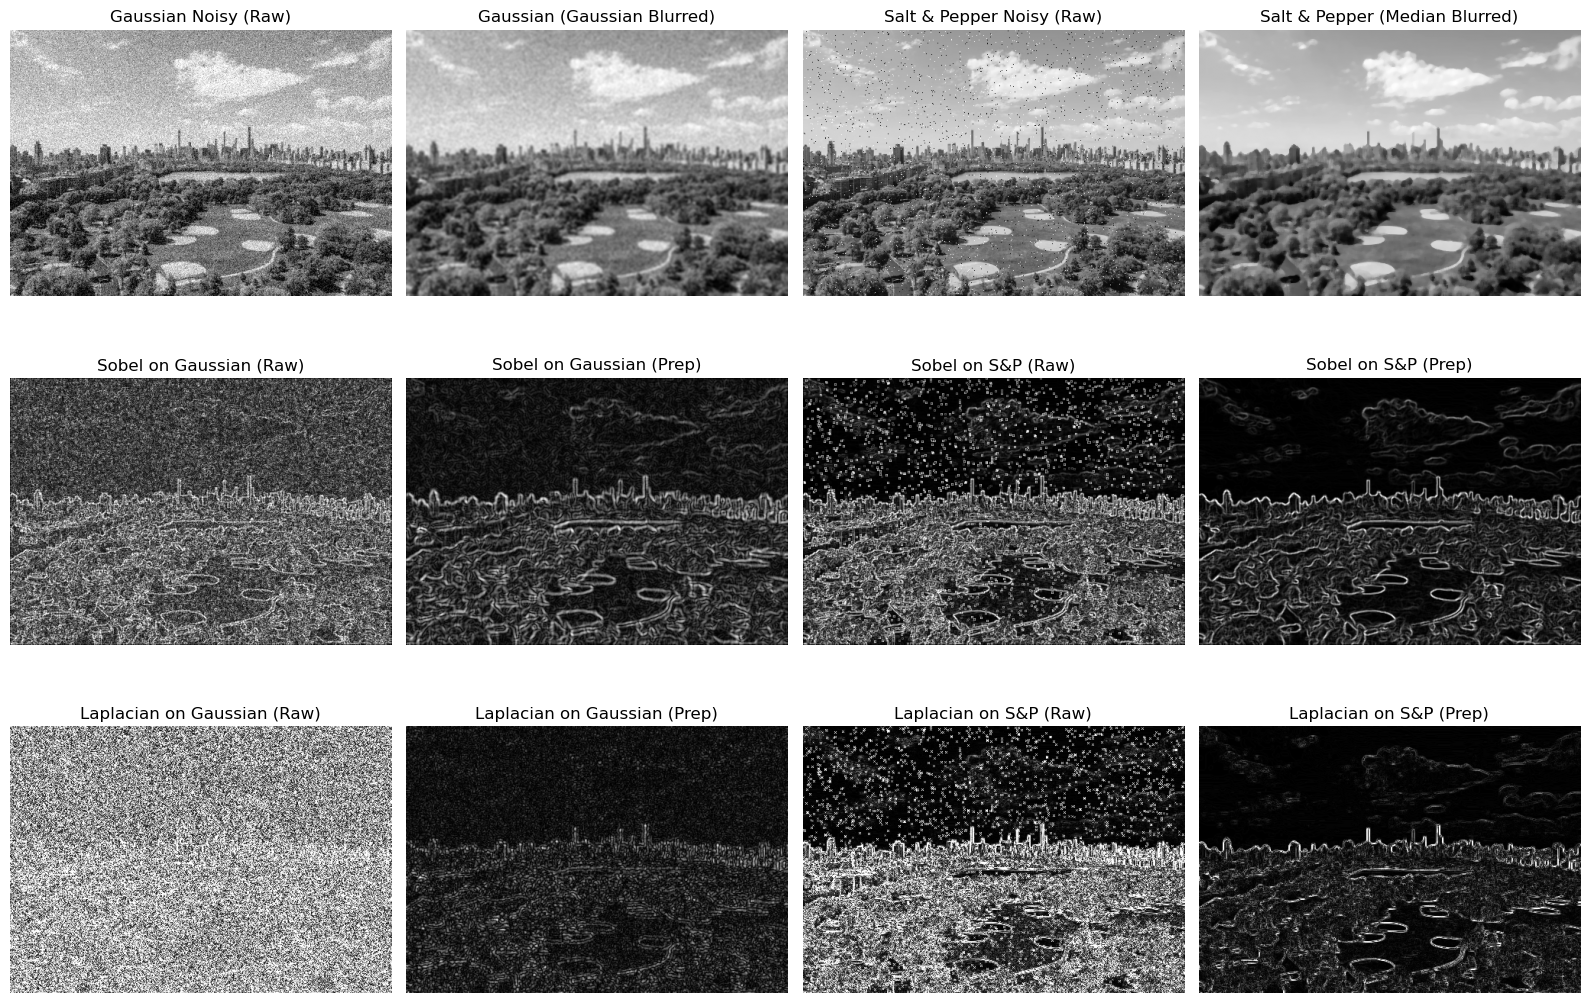

In [3]:
import matplotlib.pyplot as plt

# Also compute Sobel after preprocessing for a complete comparison
sobel_g_prep = run_sobel(prep_g)
sobel_sp_prep = run_sobel(prep_sp)

fig, axes = plt.subplots(3, 4, figsize=(16, 11))

# Row 1: Original noisy inputs & preprocessed versions
axes[0, 0].imshow(noisy_gaussian, cmap='gray')
axes[0, 0].set_title('Gaussian Noisy (Raw)')
axes[0, 1].imshow(prep_g, cmap='gray')
axes[0, 1].set_title('Gaussian (Gaussian Blurred)')
axes[0, 2].imshow(noisy_sp, cmap='gray')
axes[0, 2].set_title('Salt & Pepper Noisy (Raw)')
axes[0, 3].imshow(prep_sp, cmap='gray')
axes[0, 3].set_title('Salt & Pepper (Median Blurred)')

# Row 2: Sobel detections
axes[1, 0].imshow(sobel_g_raw, cmap='gray')
axes[1, 0].set_title('Sobel on Gaussian (Raw)')
axes[1, 1].imshow(sobel_g_prep, cmap='gray')
axes[1, 1].set_title('Sobel on Gaussian (Prep)')
axes[1, 2].imshow(sobel_sp_raw, cmap='gray')
axes[1, 2].set_title('Sobel on S&P (Raw)')
axes[1, 3].imshow(sobel_sp_prep, cmap='gray')
axes[1, 3].set_title('Sobel on S&P (Prep)')

# Row 3: Laplacian detections
axes[2, 0].imshow(lap_g_raw, cmap='gray')
axes[2, 0].set_title('Laplacian on Gaussian (Raw)')
axes[2, 1].imshow(lap_g_prep, cmap='gray')
axes[2, 1].set_title('Laplacian on Gaussian (Prep)')
axes[2, 2].imshow(lap_sp_raw, cmap='gray')
axes[2, 2].set_title('Laplacian on S&P (Raw)')
axes[2, 3].imshow(lap_sp_prep, cmap='gray')
axes[2, 3].set_title('Laplacian on S&P (Prep)')

for ax in axes.ravel():
  ax.axis('off')

plt.tight_layout()
plt.show()

1. Which operator is more affected by noise? - Laplacian is more affected
   
2. How does edge clarity change? - Unprocessed noise creates dense false edges and breaks contours, whereas preprocessing restores sharp, continuous, and clear structural boundaries


3. What preprocessing step improves the results? - Gaussian blur smooths out additive Gaussian noise

#### 3: Compression Ratio Comparison (RLE vs Huffman)

In [8]:
import heapq

# 1. Extract smooth sky region
sky = gray[0:160, :]
flat = sky.flatten()
orig_bits = len(flat) * 8

# --- A. Run-Length Encoding (RLE) ---
rle = []
count = 1
for i in range(1, len(flat)):
  if flat[i] == flat[i - 1]:
    count += 1
  else:
    rle.append((flat[i - 1], count))
    count = 1
rle.append((flat[-1], count))

# Each RLE pair: (intensity 8 bits, run count 8 bits) = 16 bits
rle_bits = len(rle) * 16
rle_reduction = ((orig_bits - rle_bits) / orig_bits) * 100

# --- B. Huffman Coding ---
freq = {}
for p in flat:
  freq[p] = freq.get(p, 0) + 1

heap = [[weight, [sym, '']] for sym, weight in freq.items()]
heapq.heapify(heap)
while len(heap) > 1:
  lo1 = heapq.heappop(heap)
  lo2 = heapq.heappop(heap)
  for pair in lo1[1:]:
    pair[1] = '0' + pair[1]
  for pair in lo2[1:]:
    pair[1] = '1' + pair[1]
  heapq.heappush(heap, [lo1[0] + lo2[0]] + lo1[1:] + lo2[1:])

huffman_dict = dict(heap[0][1:])
huffman_bits = sum(len(huffman_dict[p]) for p in flat)
huffman_reduction = ((orig_bits - huffman_bits) / orig_bits) * 100

print(f'Original Bit-Length : {orig_bits:,} bits')
print(f'RLE Bit-Length      : {rle_bits:,} bits (Reduction: {rle_reduction:.2f}%)')
print(
    f'Huffman Bit-Length  : {huffman_bits:,} bits (Reduction:'
    f' {huffman_reduction:.2f}%)'
)

Original Bit-Length : 1,114,880 bits
RLE Bit-Length      : 862,560 bits (Reduction: 22.63%)
Huffman Bit-Length  : 893,101 bits (Reduction: 19.89%)


1. Bit-length before compression: Original size was 1,114,880 bits (uncompressed 8 bits/pixel).

2. Bit-length after compression: RLE compressed to 862,560 bits, while Huffman compressed to 893,101 bits

4. Percentage reduction: RLE achieved a 22.63% reduction, and Huffman achieved a 19.89% reduction

5. Why each technique was performed

    Why RLE: compressed well by exploiting spatial redundancy across consecutive identical pixels in   smooth sky rows.

    Why Huffman: compressed by assigning shorter bit-codes to the most frequently occurring gray values across the sky's skewed histogram

#### 4: JPEG Block Artifact Analysis

In [15]:
def jpeg_compress(image, q_scale):
  h, w = image.shape[:2]
  h8, w8 = (h // 8) * 8, (w // 8) * 8
  cropped = image[:h8, :w8]

  # Standard JPEG Quantization Table from PPT/PDF
  Q = (
      np.array([
          [16, 11, 10, 16, 24, 40, 51, 61],
          [12, 12, 14, 19, 26, 58, 60, 55],
          [14, 13, 16, 24, 40, 57, 69, 56],
          [14, 17, 22, 29, 51, 87, 80, 62],
          [18, 22, 37, 56, 68, 109, 103, 77],
          [24, 35, 55, 64, 81, 104, 113, 92],
          [49, 64, 78, 87, 103, 121, 120, 101],
          [72, 92, 95, 98, 112, 100, 103, 99],
      ],
      dtype=np.float32,
  )
      * q_scale
  )
  Q = np.clip(np.round(Q), 1, 255)

  Y_float = np.float32(cropped)
  reconstructed = np.zeros_like(Y_float)

  for r in range(0, h8, 8):
    for c in range(0, w8, 8):
      block = Y_float[r : r + 8, c : c + 8]
      dct_b = cv2.dct(block)
      quant = np.round(dct_b / Q)
      dequant = quant * Q
      reconstructed[r : r + 8, c : c + 8] = cv2.idct(dequant)

  return cropped, np.clip(reconstructed, 0, 255).astype(np.uint8)


ref, rec_low = jpeg_compress(gray, 0.5)
_, rec_med = jpeg_compress(gray, 1.0)
_, rec_high = jpeg_compress(gray, 4.0)

from skimage.metrics import structural_similarity as ssim

for label, img_rec in [
    ('Low Quant (0.5x)', rec_low),
    ('Medium Quant (1.0x)', rec_med),
    ('High Quant (4.0x)', rec_high),
]:
  print(
      f'{label:<20} | PSNR: {cv2.PSNR(ref, img_rec):.2f} dB | SSIM:'
      f' {ssim(ref, img_rec):.4f}'
  )

Low Quant (0.5x)     | PSNR: 34.49 dB | SSIM: 0.9697
Medium Quant (1.0x)  | PSNR: 31.66 dB | SSIM: 0.9431
High Quant (4.0x)    | PSNR: 27.63 dB | SSIM: 0.8512


1. Where block artifacts appear: Along the boundaries between adjacent 8*8 pixel blocks, most visibly across smooth gradients and flat regions where sudden step-like discontinuities form.

2. Why some textures lose detail: High-frequency DCT coefficients that capture fine texture are aggressively divided by large quantization values and rounded down to zero.

3. How PSNR and SSIM change at each level: As quantization increases from low to high, both PSNR and SSIM drop progressively due to greater reconstruction error and structural distortion.

#### 5: Texture-Based Segmentation using GLCM Features

In [16]:
from skimage.feature import graycomatrix, graycoprops

# Patch-based GLCM feature extraction
h_orig, w_orig = gray.shape
img_small = cv2.resize(gray, (240, 160))
block_size = 8
ny, nx = img_small.shape[0] // block_size, img_small.shape[1] // block_size

glcm_features = []
for r in range(ny):
  for c in range(nx):
    patch = img_small[
        r * block_size : (r + 1) * block_size,
        c * block_size : (c + 1) * block_size,
    ]
    glcm = graycomatrix(
        patch,
        distances=[1],
        angles=[0],
        levels=256,
        symmetric=True,
        normed=True,
    )
    con = graycoprops(glcm, 'contrast')[0, 0]
    ene = graycoprops(glcm, 'energy')[0, 0]
    hom = graycoprops(glcm, 'homogeneity')[0, 0]
    glcm_features.append([con, ene, hom])

glcm_features = np.array(glcm_features, dtype=np.float32)
# Standardize features
norm_feat = (glcm_features - glcm_features.mean(axis=0)) / (
    glcm_features.std(axis=0) + 1e-6
)

# K-Means clustering (k=3)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 1.0)
_, labels, _ = cv2.kmeans(
    norm_feat, 3, None, criteria, attempts=10, flags=cv2.KMEANS_PP_CENTERS
)
seg_map = cv2.resize(
    labels.reshape((ny, nx)).astype(np.uint8),
    (w_orig, h_orig),
    interpolation=cv2.INTER_NEAREST,
)

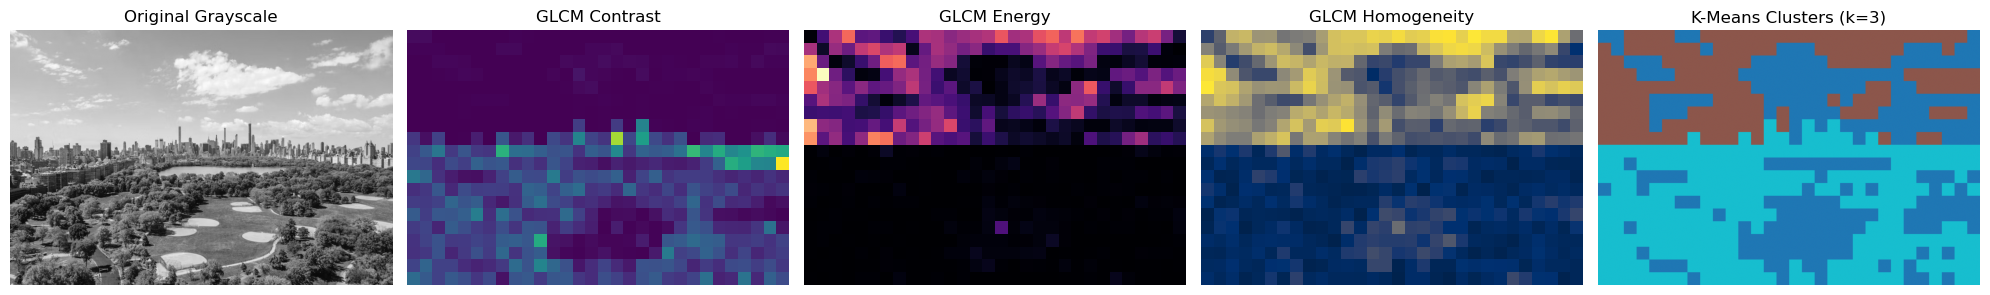

In [17]:
import matplotlib.pyplot as plt

# Reshape raw features back to patch grid for visual inspection
contrast_map = glcm_features[:, 0].reshape((ny, nx))
energy_map = glcm_features[:, 1].reshape((ny, nx))
homogeneity_map = glcm_features[:, 2].reshape((ny, nx))
segmentation_grid = labels.flatten().reshape((ny, nx))

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original Grayscale")

axes[1].imshow(contrast_map, cmap="viridis")
axes[1].set_title("GLCM Contrast")

axes[2].imshow(energy_map, cmap="magma")
axes[2].set_title("GLCM Energy")

axes[3].imshow(homogeneity_map, cmap="cividis")
axes[3].set_title("GLCM Homogeneity")

# Display final upscaled segmentation
im_seg = axes[4].imshow(seg_map, cmap="tab10")
axes[4].set_title("K-Means Clusters (k=3)")

for ax in axes:
  ax.axis("off")

plt.tight_layout()
plt.show()

#### 6: Multi-Feature Segmentation for Disease Detection

In [13]:
# 1. Feature 1: Intensity
feat1_intensity = gray.copy()

# 2. Feature 2: Sobel Gradient Magnitude
sx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag = np.sqrt(sx**2 + sy**2)
feat2_sobel = cv2.normalize(
    sobel_mag, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

# 3. Feature 3: Local Texture Variance (3x3 neighborhood from slides)
kernel = np.ones((3, 3), np.float32) / 9.0
local_mean = cv2.filter2D(gray, -1, kernel)
local_var = (gray - local_mean) ** 2
feat3_variance = cv2.normalize(
    local_var, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

# 4. Multi-feature stack (H x W x 3)
fv = np.stack([feat1_intensity, feat2_sobel, feat3_variance], axis=2)
fv_flat = fv.reshape((-1, 3)).astype(np.float32)

# 5. K-Means (k=3)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 1.0)
_, labels, _ = cv2.kmeans(
    fv_flat, 3, None, criteria, attempts=10, flags=cv2.KMEANS_PP_CENTERS
)
segmented_multifeature = labels.reshape(gray.shape)

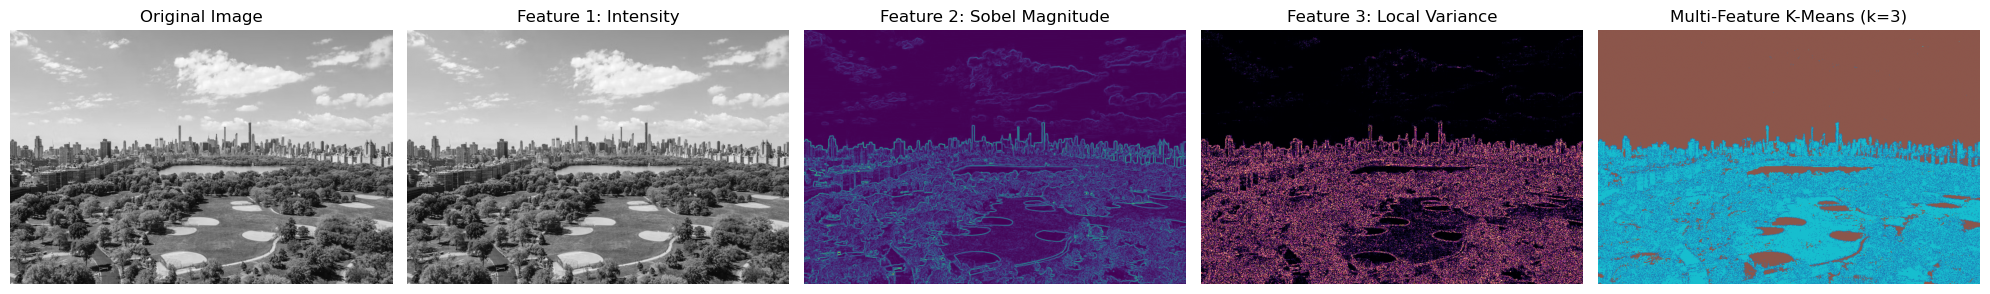

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(feat1_intensity, cmap="gray")
axes[1].set_title("Feature 1: Intensity")

axes[2].imshow(feat2_sobel, cmap="viridis")
axes[2].set_title("Feature 2: Sobel Magnitude")

axes[3].imshow(feat3_variance, cmap="magma")
axes[3].set_title("Feature 3: Local Variance")

# Display the 3-cluster segmentation
axes[4].imshow(segmented_multifeature, cmap="tab10")
axes[4].set_title("Multi-Feature K-Means (k=3)")

for ax in axes:
  ax.axis("off")

plt.tight_layout()
plt.show()